# Assignment Five - Stock Price Predictions
Aylie Lapierre Nagler, Anika Viado, Qlirim Teneqja, Arsi Kharghani<br>
COMP-3704 Neural Networks and Deep Learning<br>
November 12, 2026<br>

## Objective
To build a time sequence model for predicting short term future stock prices from historical data.

## Data
Historical stock price data on US-based stocks, last updated in 2017. The dataset is available at [Huge Stock Market Dataset | Kaggle](https://www.kaggle.com/datasets/borismarjanovic/price-volume-data-for-all-us-stocks-etfs) and is provided by Boris Marjanovic. A list of stock ticker symbols is available at [List of All Stock Ticker Symbols - Stock Analysis](https://stockanalysis.com/stocks/), to help identify the name of the stock from the txt file name.

## Problem Statement
An investment company is interested in learning about the potential profit in frequent buy/sell stock transactions. A time sequence model is developed to predict the price two days ahead based on recent prices. Four (or more) of the data files are used for training and a separate two for validation. Once the model is finalized, two other data files are used for testing to demonstrate how well the model makes predictions.

## Data Preparation

### <span style="color:royalblue">Import Libraries</span>

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

### <span style="color:royalblue">Selecting the Data Files</span>

Our chosen stocks have a variety of date ranges starting as early as 1970 and as late as 2005. To ensure that all stocks are respresented equally we will take a slice of time that includes all stocks. We will use data starting on Nov 10 2007 up until the latest entries on Nov 10 2017.

In [ ]:
train_files = ['lmt.us.txt', 'gs.us.txt', 'cost.us.txt', 'dal.us.txt']
val_files = ['aapl.us.txt', 'ko.us.txt']
test_files = ['nvda.us.txt', 'atvi.us.txt']

In [4]:
companies = {
    'lmt': 'Lockheed Martin',
    'gs': 'Goldman Sachs',
    'cost': 'Costco',
    'dal': 'Delta Air Lines',
    'aapl': 'Apple',
    'ko': 'Coca-Cola',
    'nvda': 'NVIDIA',
    'atvi': 'Activision Blizzard'
}


### <span style="color:royalblue">Closing Price Plots</span>

c:\Users\aylie\anaconda3\envs\rrc-nn-dl\lib\site-packages\pandas\plotting\_matplotlib\converter.py:103: FutureWarning: Using an implicitly registered datetime converter for a matplotlib plotting method. The converter was registered by pandas on import. Future versions of pandas will require you to explicitly register matplotlib converters.

To register the converters:
	>>> from pandas.plotting import register_matplotlib_converters
	>>> register_matplotlib_converters()
  warnings.warn(msg, FutureWarning)


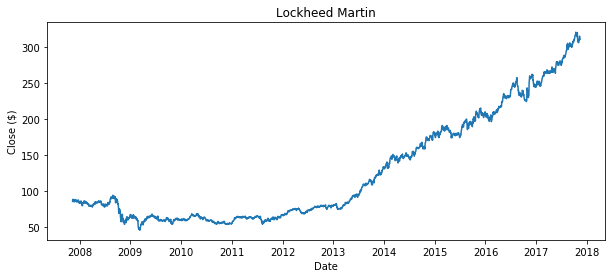

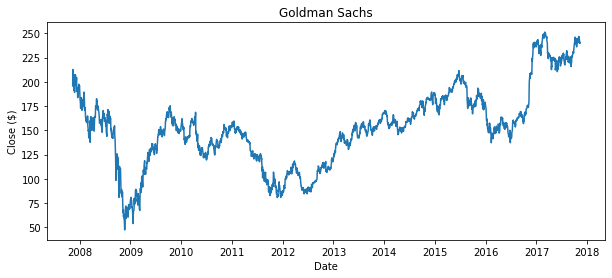

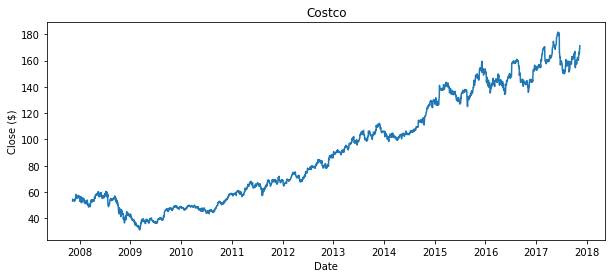

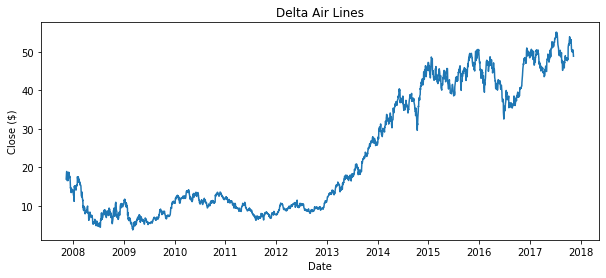

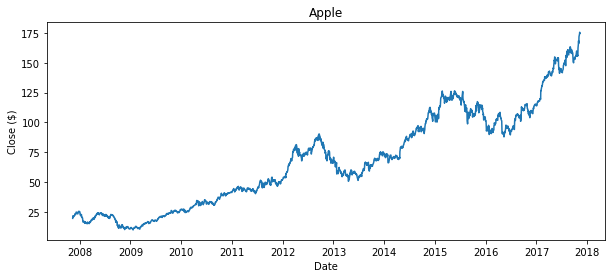

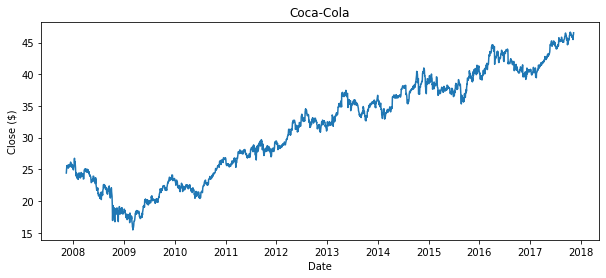

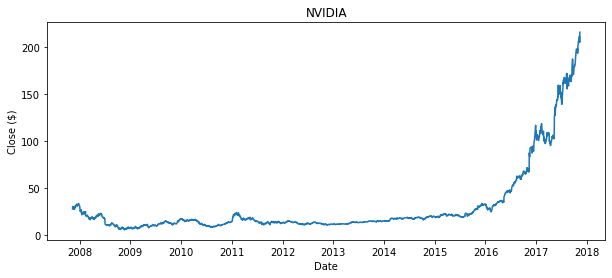

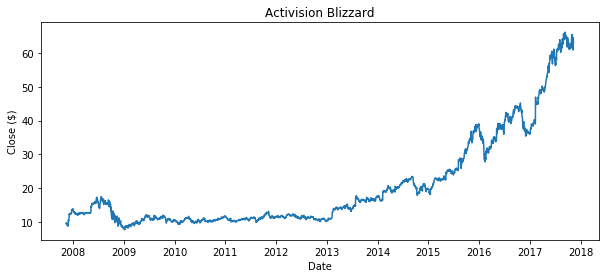

In [5]:
all_files = train_files + val_files + test_files

for f in all_files:
    df = pd.read_csv('../DATA/' + f, parse_dates=['Date'])
    df = df[df['Date'] >= '2007-11-10']
    
    ticker = f.split('.')[0]

    plt.figure(figsize=(10, 4))
    plt.plot(df['Date'], df['Close'])
    plt.title(companies[ticker])
    plt.xlabel('Date')
    plt.ylabel('Close ($)')
    plt.show()

### <span style="color:royalblue">Sequence Loading Function</span>

In [6]:
def get_lookback(file, look_back):
    df = pd.read_csv('../DATA/' + file, parse_dates=['Date'])
    df = df[df['Date'] >= '2007-11-10']

    y = df[['Close']].reset_index(drop=True)
    dataX = [y.shift(i) for i in range(2, look_back + 2)]
    dataX = pd.concat(dataX, axis=1)

    keep = dataX.notna().all(axis=1)
    return dataX[keep].values, y[keep].values

### <span style="color:royalblue">Loading and Concatenating the Data</span>

In [7]:
look_back = 10

def load_files(files, look_back):
    X_list = []
    y_list = []
    for file in files:
        X, y = get_lookback(file, look_back)
        X_list.append(X)
        y_list.append(y)
    return np.concatenate(X_list), np.concatenate(y_list)

X_train, y_train = load_files(train_files, look_back)
X_val, y_val = load_files(val_files, look_back)
X_test, y_test = load_files(test_files, look_back)

print('Train:', X_train.shape, y_train.shape)
print('Val:  ', X_val.shape, y_val.shape)
print('Test: ', X_test.shape, y_test.shape)

Train: (10032, 10) (10032, 1)
Val:   (5016, 10) (5016, 1)
Test:  (5015, 10) (5015, 1)


### <span style="color:royalblue">Scaling</span>

In [8]:
scaler = MinMaxScaler()
scaler.fit(y_train)

def scale(data):
    return scaler.transform(data.reshape(-1, 1)).reshape(data.shape)

X_train_scaled = scale(X_train)
y_train_scaled = scale(y_train)
X_val_scaled = scale(X_val)
y_val_scaled = scale(y_val)
X_test_scaled = scale(X_test)
y_test_scaled = scale(y_test)

## Modeling

### <span style="color:royalblue">Model 1</span>

#### <span style="color:cornflowerblue">Training Loss</span>

#### <span style="color:cornflowerblue">Validation Loss</span>

#### <span style="color:cornflowerblue">Validation Predictions</span>

### <span style="color:royalblue">Model 2</span>

#### <span style="color:cornflowerblue">Training Loss</span>

#### <span style="color:cornflowerblue">Validation Loss</span>

#### <span style="color:cornflowerblue">Validation Predictions</span>

### <span style="color:royalblue">Model 3</span>

#### <span style="color:cornflowerblue">Training Loss</span>

#### <span style="color:cornflowerblue">Validation Loss</span>

#### <span style="color:cornflowerblue">Validation Predictions</span>

### <span style="color:royalblue">Model Comparison</span>

#### <span style="color:cornflowerblue">Training and Validation Loss</span>

#### <span style="color:cornflowerblue">Predicted vs Actual Prices</span>

#### <span style="color:cornflowerblue">Best Model Selection</span>

### <span style="color:royalblue">Testing the Best Model</span>

#### <span style="color:cornflowerblue">Testing Loss</span>

#### <span style="color:cornflowerblue">Predictions vs True Values</span>

## Discussion

### <span style="color:royalblue">Best Model Selection</span>

#### <span style="color:cornflowerblue">Zooming In on Problem Areas</span>

#### <span style="color:cornflowerblue">Justification</span>

### <span style="color:royalblue">Predicting Two Days Ahead</span>

#### <span style="color:cornflowerblue">Estimated Prediction Error</span>

## References

## AI Statement